In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [10]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")

In [11]:
print(df.shape)

(71913, 17)


In [ ]:
print(df.info())

In [13]:
print(df.head())

   work_year experience_level employment_type       job_title  salary  \
0       2025               EX              FT    Head of Data  348516   
1       2025               EX              FT    Head of Data  232344   
2       2025               SE              FT  Data Scientist  145400   
3       2025               SE              FT  Data Scientist   81600   
4       2025               MI              FT        Engineer  160000   

  salary_currency  salary_in_usd employee_residence  remote_ratio  \
0             USD         348516                 US             0   
1             USD         232344                 US             0   
2             USD         145400                 US             0   
3             USD          81600                 US             0   
4             USD         160000                 US           100   

  company_location company_size experience_level_label employment_type_label  \
0               US            M        Executive-level            

In [14]:
print(df.describe())

print(df.describe(include="object"))

          work_year        salary  salary_in_usd  remote_ratio
count  71913.000000  7.191300e+04   71913.000000  71913.000000
mean    2024.425153  1.617102e+05  151161.252625     24.569271
std        0.721198  2.872868e+05   77329.594122     42.917779
min     2020.000000  1.400000e+04   15000.000000      0.000000
25%     2024.000000  9.640000e+04   96000.000000      0.000000
50%     2025.000000  1.397000e+05  138750.000000      0.000000
75%     2025.000000  1.922000e+05  190315.000000      0.000000
max     2025.000000  3.040000e+07  800000.000000    100.000000
       experience_level employment_type       job_title salary_currency  \
count             71913           71913           71913           71913   
unique                4               4             422              26   
top                  SE              FT  Data Scientist             USD   
freq              37702           71163            7160           65910   

       employee_residence company_location company_size  

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
work_year                     0
experience_level              0
employment_type               0
job_title                     0
salary                        0
salary_currency               0
salary_in_usd                 0
employee_residence            0
remote_ratio                  0
company_location              0
company_size                  0
experience_level_label        0
employment_type_label         0
work_mode                     0
salary_outlier_flag           0
role_family                   0
isco_group_hint           40540
dtype: int64


isco_group_hint    40540
dtype: int64


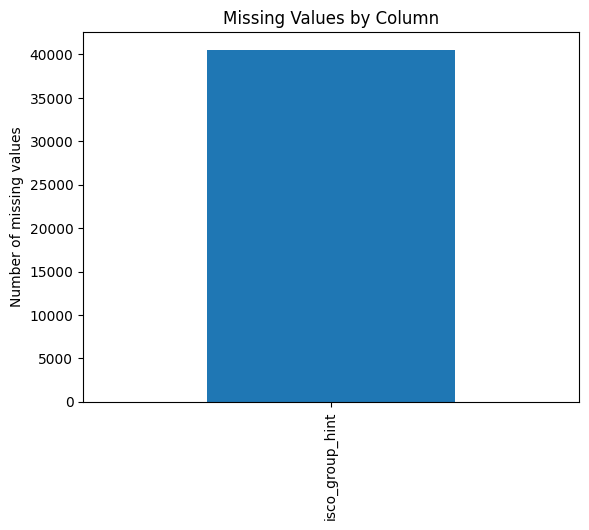

In [17]:
missing = df.isnull().sum()

print(missing[missing > 0])


missing[missing > 0].sort_values().plot(
    kind="bar",
    title="Missing Values by Column"
)

plt.ylabel("Number of missing values")
plt.show()

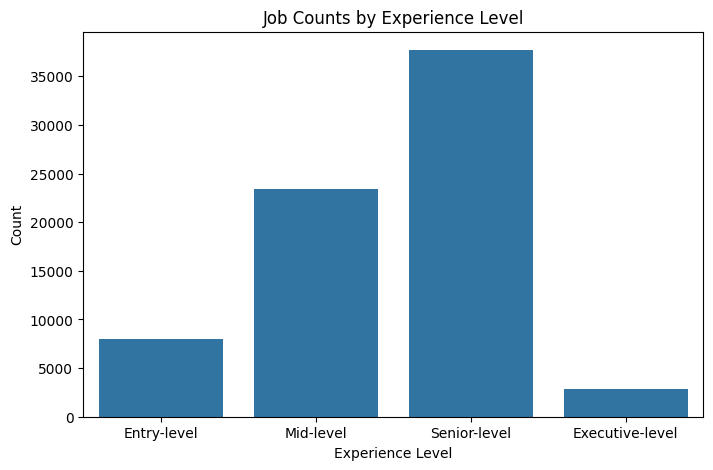

In [19]:
order = ["Entry-level", "Mid-level", "Senior-level", "Executive-level"]

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="experience_level_label", order=order)
plt.title("Job Counts by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Count")
plt.show()

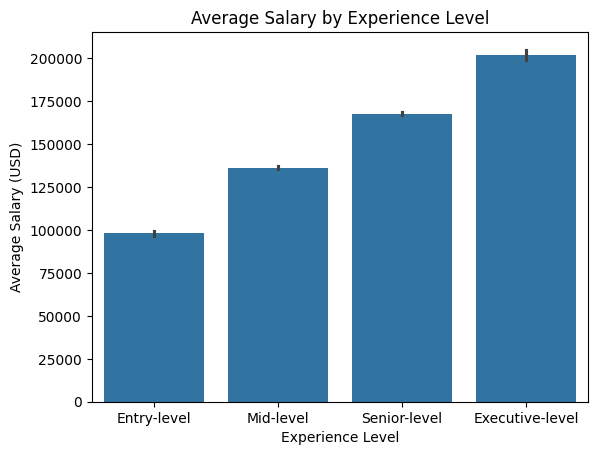

In [20]:
sns.barplot(
    data=df,
    x="experience_level_label",
    y="salary_in_usd",
    order=order
)

plt.title("Average Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary (USD)")
plt.show()

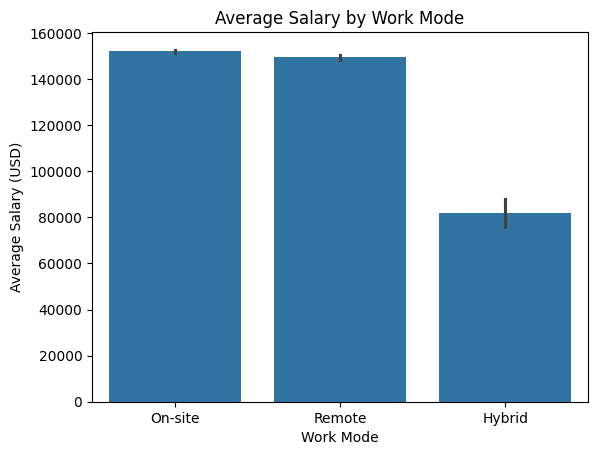

In [21]:
sns.barplot(
    data=df,
    x="work_mode",
    y="salary_in_usd"
)

plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (USD)")
plt.show()


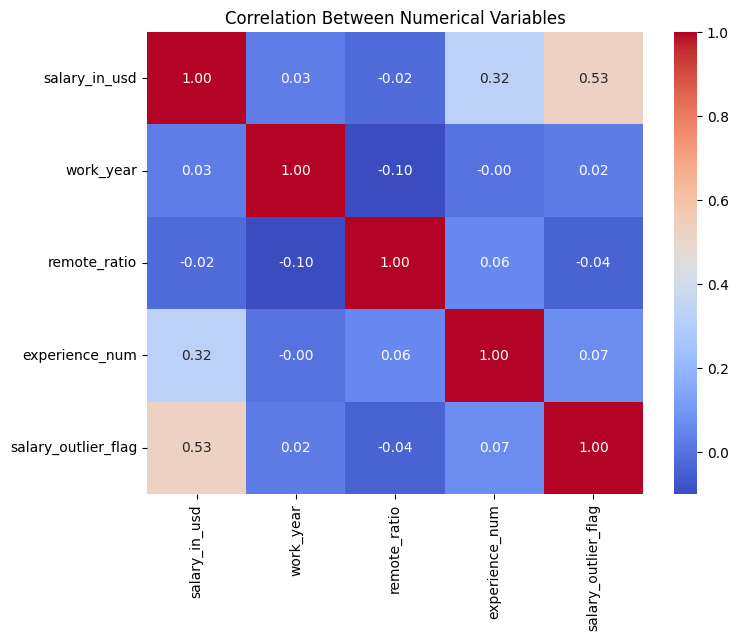

In [22]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["experience_num"] = df["experience_level"].map(level_map)

df["salary_outlier_flag"] = df["salary_outlier_flag"].astype(int)

cols = ["salary_in_usd", "work_year", "remote_ratio",
        "experience_num", "salary_outlier_flag"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

In [23]:
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Dataset shape: (71913, 18)


In [25]:
df["IscoKnown"] = df["isco_group_hint"].notna().astype(int)

df = df.drop(columns=["isco_group_hint"])

In [26]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["ExperienceNum"] = df["experience_level"].map(level_map)

df["IsRemote"] = (df["remote_ratio"] == 100).astype(int)

df["WorksAbroad"] = (df["employee_residence"] != df["company_location"]).astype(int)
df["IsSenior"] = df["experience_level"].isin(["SE", "EX"]).astype(int)

print(
    df[["experience_level", "ExperienceNum", "remote_ratio", "IsRemote",
        "WorksAbroad", "IsSenior"]].head()
)

  experience_level  ExperienceNum  remote_ratio  IsRemote  WorksAbroad  \
0               EX              4             0         0            0   
1               EX              4             0         0            0   
2               SE              3             0         0            0   
3               SE              3             0         0            0   
4               MI              2           100         1            0   

   IsSenior  
0         1  
1         1  
2         1  
3         1  
4         0  


In [29]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["ExperienceNum"] = df["experience_level"].map(level_map)
df["IsRemote"] = (df["remote_ratio"] == 100).astype(int)
df["WorksAbroad"] = (df["employee_residence"] != df["company_location"]).astype(int)
df["IsSenior"] = df["experience_level"].isin(["SE", "EX"]).astype(int)

# ---- Target ----
df["HighSalary"] = (df["salary_in_usd"] > df["salary_in_usd"].median()).astype(int)

# ---- Features and target ----
X = df[
    ["ExperienceNum", "company_size", "work_year", "employment_type",
     "role_family", "IsRemote", "WorksAbroad", "IsSenior"]
]
y = df["HighSalary"]

print("Features:")
print(X.head())
print("Target:")
print(y.head())

Features:
   ExperienceNum company_size  work_year employment_type  \
0              4            M       2025              FT   
1              4            M       2025              FT   
2              3            M       2025              FT   
3              3            M       2025              FT   
4              2            M       2025              FT   

            role_family  IsRemote  WorksAbroad  IsSenior  
0     Analytics Manager         0            0         1  
1     Analytics Manager         0            0         1  
2        Data Scientist         0            0         1  
3        Data Scientist         0            0         1  
4  Other / Unclassified         1            0         0  
Target:
0    1
1    1
2    1
3    0
4    1
Name: HighSalary, dtype: int64


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("Training class proportions:")
print(y_train.value_counts(normalize=True))

print("Testing class proportions:")
print(y_test.value_counts(normalize=True))

Training rows: 57530
Testing rows: 14383
Training class proportions:
HighSalary
0    0.50007
1    0.49993
Name: proportion, dtype: float64
Testing class proportions:
HighSalary
0    0.500104
1    0.499896
Name: proportion, dtype: float64


In [31]:
numeric_features = [
    "ExperienceNum", "work_year",
    "IsRemote", "WorksAbroad", "IsSenior"
]

categorical_features = [
    "company_size", "employment_type", "role_family"
]

In [32]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [34]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False))
])


In [35]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [36]:
X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Training shape: (57530, 23)
Testing shape: (14383, 23)


In [37]:
print("Missing values in training:",
      np.isnan(X_train_prepared).sum())

print("Missing values in testing:",
      np.isnan(X_test_prepared).sum())

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Missing values in training: 0
Missing values in testing: 0
Training target shape: (57530,)
Testing target shape: (14383,)


# New Section